# Quantum Chemistry on a Quantum Computer with Qiskit Nature: the Hydrogen Molecule

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

Prof. Victor S. Batista

**Version 2.0 · November 2026 · runs on Google Colab with a standard CPU runtime (no GPU needed); uses Qiskit Nature 0.8, Qiskit Algorithms 0.4 and PySCF.**
**How to cite:** V. S. Batista, *Quantum chemistry on a quantum computer with Qiskit Nature: the hydrogen molecule*, CHEM 584 tutorial notebook, version 2.0 (2026).

## 1. Introduction

The properties of a molecule (its shape, its stability, how it reacts) are determined by the behaviour of its electrons, and that behaviour is governed by the Schrödinger equation. The equation cannot be solved exactly for more than a handful of electrons, and the cost of *approximate* methods that are accurate grows very quickly with the size of the molecule. This is one of the most promising application areas for quantum computers: a quantum computer can represent the quantum state of the electrons naturally. **Qiskit Nature** is an open-source framework that connects the two worlds: it takes a molecule, lets a classical chemistry program (the *driver*, here PySCF) compute the ingredients, and translates the problem into a form that a quantum algorithm can handle.

In this tutorial we follow the complete pipeline on the simplest molecule there is, **H₂**, and we do it in a way that you can *check*: at every step we compare with an exact result that can be computed classically for such a small problem.

### What you will learn
After working through this notebook you will be able to:
1. state the electronic structure problem of a molecule and explain what **second quantization** and a **basis set** are;
2. explain how fermionic operators are mapped to qubit operators (**Jordan-Wigner** and **parity** mappings) and how symmetries remove two qubits for H₂;
3. explain the **variational principle** and write a **variational quantum eigensolver (VQE)** from scratch with Qiskit primitives and SciPy;
4. run the full Qiskit Nature pipeline (driver → problem → mapper → ansatz → VQE → result) and interpret every part of its output;
5. **validate** the result against exact diagonalisation and Hartree-Fock, compute a **potential energy curve**, and see where Hartree-Fock fails and VQE does not;
6. explain why the *statistical noise* of quantum measurements makes **chemical accuracy** hard to reach.

### What you need
Basic Python and a first acquaintance with qubits and quantum gates. The chemistry and the mathematics that we need are explained in Section 2.

### Roadmap

| Section | Content |
|---|---|
| 2 | Background: the electronic structure problem, second quantization, qubit mappings, VQE |
| 3 | Setup: install, settings, imports |
| 4 | Warm-up: H₂ with two qubits and VQE from scratch |
| 5 | The Qiskit Nature pipeline, step by step, with validation |
| 6 | The potential energy curve of H₂ |
| 7 | Measurement noise and chemical accuracy |
| 8 | What now? Exercises, questions, references |

> **What changed since 2022.** The first version of this notebook used `qiskit_nature.drivers`, `ElectronicStructureProblem(driver)`, `QubitConverter`, `qiskit.algorithms.VQE(quantum_instance=...)` and `qiskit.Aer`. These interfaces no longer exist. Today: `driver.run()` returns the problem, a **mapper** (`mapper.map(...)`) replaces the converter, algorithms live in the separate `qiskit_algorithms` package, and circuits are executed through **primitives** (here the `StatevectorEstimator`) instead of a quantum instance with a backend.

**How to run.** Run the cells from top to bottom. Cells whose code is hidden (form cells) are plumbing or figures; click *Show code* to see them.

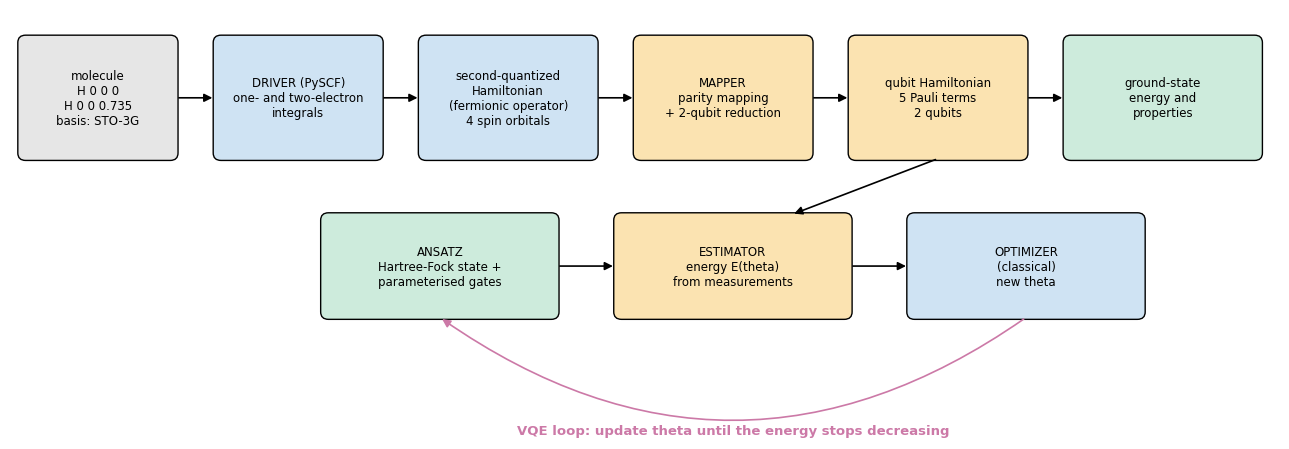

In [1]:
#@title Figure 1: the pipeline at a glance { display-mode: "form" }
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="k", lw=1))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color="k", rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=12, lw=1.2, color=color, connectionstyle=f"arc3,rad={rad}"))

fig, ax = plt.subplots(figsize=(13, 4.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis("off")
blue, orange, green, gray = "#cfe3f3", "#fbe3b1", "#cdebdc", "#e6e6e6"
box(ax, 0.1, 3.0, 1.6, 1.3, "molecule\nH 0 0 0\nH 0 0 0.735\nbasis: STO-3G", gray)
box(ax, 2.1, 3.0, 1.7, 1.3, "DRIVER (PySCF)\none- and two-electron\nintegrals", blue)
box(ax, 4.2, 3.0, 1.8, 1.3, "second-quantized\nHamiltonian\n(fermionic operator)\n4 spin orbitals", blue)
box(ax, 6.4, 3.0, 1.8, 1.3, "MAPPER\nparity mapping\n+ 2-qubit reduction", orange)
box(ax, 8.6, 3.0, 1.8, 1.3, "qubit Hamiltonian\n5 Pauli terms\n2 qubits", orange)
box(ax, 10.8, 3.0, 2.0, 1.3, "ground-state\nenergy and\nproperties", green)
for x0, x1 in [(1.7, 2.1), (3.8, 4.2), (6.0, 6.4), (8.2, 8.6), (10.4, 10.8)]:
    arrow(ax, (x0, 3.65), (x1, 3.65))
box(ax, 3.2, 1.3, 2.4, 1.1, "ANSATZ\nHartree-Fock state +\nparameterised gates", green)
box(ax, 6.2, 1.3, 2.4, 1.1, "ESTIMATOR\nenergy E(theta)\nfrom measurements", orange)
box(ax, 9.2, 1.3, 2.4, 1.1, "OPTIMIZER\n(classical)\nnew theta", blue)
arrow(ax, (5.6, 1.85), (6.2, 1.85)); arrow(ax, (8.6, 1.85), (9.2, 1.85))
arrow(ax, (9.5, 3.0), (8.0, 2.4))                                    # the Hamiltonian goes to the estimator
arrow(ax, (10.4, 1.3), (4.4, 1.3), color="#CC79A7", rad=-0.35)         # feedback: new parameters back to the ansatz (drawn below the boxes)
ax.text(7.4, 0.05, "VQE loop: update theta until the energy stops decreasing", color="#CC79A7", ha="center", fontsize=9.5, weight="bold")
plt.tight_layout(); plt.show()

**Figure 1.** The pipeline of this tutorial. A classical chemistry program (blue) turns the molecule into a Hamiltonian in second quantization. A mapper (orange) converts it into a Hamiltonian acting on qubits. The **variational quantum eigensolver (VQE)** then searches for the ground state: a parameterised circuit prepares a trial state, an estimator measures its energy, and a classical optimiser changes the parameters until the energy stops decreasing (the VQE loop). The result is the ground-state energy and other properties of the molecule.

## 2. Background

### 2.1 The electronic structure problem
Because the nuclei are much heavier than the electrons, we treat them as **fixed** (the Born-Oppenheimer approximation) and solve the Schrödinger equation of the electrons alone, for each arrangement $R$ of the nuclei. In atomic units (energies in **Hartree**, lengths in **bohr**; 1 Hartree = 27.211 eV and 1 bohr = 0.529177 Å) the *electronic Hamiltonian* is
$$H_{\rm el}=-\sum_i\tfrac12\nabla_i^2\;-\;\sum_{i,A}\frac{Z_A}{|r_i-R_A|}\;+\;\sum_{i<j}\frac1{|r_i-r_j|},$$
(kinetic energy of the electrons, attraction to the nuclei, repulsion between electrons). The nuclei repel each other with a constant energy $E_{\rm nuc}=\sum_{A<B}Z_AZ_B/|R_A-R_B|$. The **total energy** at geometry $R$ is $E(R)=E_{\rm el}(R)+E_{\rm nuc}(R)$, where $E_{\rm el}$ is the lowest eigenvalue of $H_{\rm el}$ (the **ground-state energy**). Computing $E(R)$ for many $R$ gives the *potential energy curve* from which we read the equilibrium bond length, vibrational frequencies and the energy needed to break the bond.

For H₂ the nuclear repulsion is $1/R$ with $R$ in bohr: at $0.735$ Å ($=1.389$ bohr) it is $0.71997$ Hartree.

### 2.2 Basis sets and second quantization
We cannot work with functions of continuous space on a computer, so we expand the molecular orbitals in a finite **basis set**. We use the minimal basis **STO-3G**: one function (a combination of three Gaussians) for the $1s$ orbital of each hydrogen atom. Two basis functions give two **spatial molecular orbitals**: a bonding orbital $\sigma_g$ and an antibonding orbital $\sigma_u$. Each can hold an electron of spin up ($\alpha$) or down ($\beta$), so there are $2\times2=4$ **spin orbitals**.

In **second quantization** a state is described by which spin orbitals are occupied. For $M$ spin orbitals each is empty or occupied, so the state space (the *Fock space*) has dimension $2^M$ ($=16$ for H₂). Creation and annihilation operators $a_p^\dagger$ and $a_p$ add or remove an electron in spin orbital $p$ and obey $\{a_p,a_q^\dagger\}=\delta_{pq}$ (the Pauli principle). The electronic Hamiltonian becomes
$$H_{\rm el}=\sum_{pq}h_{pq}\,a_p^\dagger a_q\;+\;\frac12\sum_{pqrs}h_{pqrs}\,a_p^\dagger a_q^\dagger a_r a_s ,$$
where the numbers $h_{pq}$ (one-electron integrals) and $h_{pqrs}$ (two-electron integrals) are computed **classically** by the driver. This is the "fermionic operator" in Figure 1.

With 2 electrons in 4 spin orbitals there are $\binom42=6$ states; 4 of them have zero total spin projection. In the **Hartree-Fock (HF)** approximation the two electrons occupy the bonding orbital $\sigma_g$ (one $\alpha$, one $\beta$): a *single* electronic configuration. The exact ground state (the *full configuration interaction*, FCI, solution in this basis) is a superposition of that configuration and the doubly excited one ($\sigma_u^2$). The energy difference is the **correlation energy**.

### 2.3 From fermions to qubits
A quantum computer manipulates qubits, not fermions, so we need a **mapping** that turns the operators $a_p,a_p^\dagger$ into sums of products of Pauli matrices (*Pauli strings*) while preserving the anticommutation rules.

* **Jordan-Wigner (JW).** Qubit $p$ stores the occupation of spin orbital $p$ ($|0\rangle$: empty, $|1\rangle$: occupied). To enforce the fermionic sign, $a_p=Z_0Z_1\cdots Z_{p-1}\otimes\tfrac12(X_p+iY_p)$: the string of $Z$ operators counts the electrons in the orbitals before $p$. H₂ needs **4 qubits**.
* **Parity mapping.** Qubit $p$ stores the *parity* of the number of electrons in the orbitals $0,\dots,p$ (the sum modulo 2).

**Removing two qubits.** The Hamiltonian conserves the number of $\alpha$ electrons and the number of $\beta$ electrons. In the parity encoding (with the $\alpha$ orbitals first, then the $\beta$ orbitals) two of the qubits store exactly these conserved parities, so they only ever appear as the Pauli operators $Z$ or $I$ in $H$ and can be fixed to $\pm1$ and *removed*. For H₂ this reduces **4 qubits to 2**, without any approximation, as long as we stay in the sector with one $\alpha$ and one $\beta$ electron. Such a reduction is especially valuable on today's quantum computers, where every qubit counts.

### 2.4 The variational principle and VQE
For *any* normalised state $|\psi\rangle$ the energy cannot be below the ground-state energy $E_0$:
$$E[\psi]=\langle\psi|H|\psi\rangle\;\ge\;E_0 .$$
So we can find $E_0$ by **minimising** over a family of states $|\psi(\boldsymbol\theta)\rangle=U(\boldsymbol\theta)|\psi_{\rm HF}\rangle$ produced by a parameterised circuit (the **ansatz**) that starts from the Hartree-Fock state. Writing $H=\sum_kc_kP_k$ as a sum of Pauli strings, the energy is $E(\boldsymbol\theta)=\sum_kc_k\langle\psi(\boldsymbol\theta)|P_k|\psi(\boldsymbol\theta)\rangle$: each term is measured on the quantum computer (the job of the **estimator**), the sum is formed classically, and a classical **optimiser** updates $\boldsymbol\theta$. That is the **variational quantum eigensolver (VQE)** of Figure 1.

* The standard chemistry-inspired ansatz is **UCCSD** (unitary coupled cluster with singles and doubles): $U=e^{T-T^\dagger}$, where $T$ contains single and double *excitations* (moving one or two electrons from occupied to empty orbitals) with amplitudes $\boldsymbol\theta$. With $\boldsymbol\theta=0$ it returns exactly the HF state, which is why the optimisation starts at zero.
* The accuracy that chemistry asks for is **chemical accuracy**: $1.6\times10^{-3}$ Hartree ($\approx$ 1 kcal/mol), because chemical reaction energies and rates depend sensitively on energy differences of that size.

## 3. Setup

### 3.1 Install the packages
We need Qiskit Nature, the separate `qiskit-algorithms` package (VQE and optimisers), the chemistry program **PySCF** that computes the integrals, and `py3Dmol` for 3D molecule views. `pylatexenc` lets Qiskit draw circuits. `pip` chooses a version of Qiskit that is compatible with Qiskit Nature.

> Qiskit Nature supports several drivers: PySCF (open source, used here), Psi4 and the commercial Gaussian 16. PySCF is the easiest to install.

In [2]:
#@title Install the packages { display-mode: "form" }
%pip install -q qiskit-nature qiskit-algorithms pyscf py3Dmol pylatexenc

### 3.2 Settings
| Setting | Meaning |
|---|---|
| `BOND_LENGTH` | H-H distance in Å for the main calculation (Section 5) |
| `BASIS` | basis set of the calculation (`sto3g` is the minimal basis) |
| `SEED` | random seed (noise experiment) |
| `N_REPEATS` | number of repeated optimisations per precision in Section 7 |

(The warm-up of Section 4 uses a Hamiltonian that is valid for 0.735 Å only.)

In [3]:
#@title Settings { display-mode: "form" }
BOND_LENGTH = 0.735 #@param {type:"number"}
BASIS = "sto3g" #@param {type:"string"}
SEED = 0 #@param {type:"integer"}
N_REPEATS = 20 #@param {type:"integer"}

### 3.3 Imports and versions

In [4]:
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=DeprecationWarning, module="qiskit")      # keep the output readable

import qiskit, qiskit_nature, qiskit_algorithms, pyscf, py3Dmol
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp

from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper, ParityMapper, BravyiKitaevMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.algorithms import GroundStateEigensolver

from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import L_BFGS_B

from pyscf import gto, scf

COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")   # colour-blind safe
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(SEED)

HARTREE_TO_KCAL = 627.509            # 1 Hartree in kcal/mol
CHEMICAL_ACCURACY = 1.5936e-3        # 1 kcal/mol in Hartree
BOHR_PER_ANGSTROM = 1 / 0.529177249

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | qiskit {qiskit.__version__} | "
      f"qiskit-nature {qiskit_nature.__version__} | qiskit-algorithms {getattr(qiskit_algorithms, '__version__', '?')} | pyscf {pyscf.__version__}")

python 3.13.18 | numpy 2.4.6 | qiskit 2.6.2 | qiskit-nature 0.8.0 | qiskit-algorithms 0.4.0 | pyscf 2.15.0


### 3.4 The molecule
Here is H₂ at the chosen bond length as an interactive 3D view (drag to rotate). Because the nuclei are fixed, the **nuclear repulsion energy** is simply $1/R$ with $R$ in bohr, a number that we will meet again in the results.

In [5]:
xyz = f"2\nH2\nH 0.0 0.0 0.0\nH 0.0 0.0 {BOND_LENGTH}\n"
view = py3Dmol.view(width=360, height=240)
view.addModel(xyz, "xyz")
view.setStyle({"stick": {"radius": 0.12}, "sphere": {"scale": 0.28}})
view.addLabel(f"{BOND_LENGTH} Angstrom", {"fontSize": 12, "fontColor": "black", "backgroundColor": "white", "backgroundOpacity": 0.7,
                                         "useScreen": True, "alignment": "topLeft"})
view.zoomTo()
view.show()
print(f"nuclear repulsion energy 1/R = {1 / (BOND_LENGTH * BOHR_PER_ANGSTROM):.6f} Hartree  (R = {BOND_LENGTH * BOHR_PER_ANGSTROM:.4f} bohr)")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

nuclear repulsion energy 1/R = 0.719969 Hartree  (R = 1.3889 bohr)


## 4. Warm-up: H₂ with two qubits, and VQE from scratch

Before using any chemistry package, let's see the whole idea at work with a Hamiltonian that is small enough to write down. For H₂ at 0.735 Å in the STO-3G basis, after the parity mapping and the two-qubit reduction (Section 2.3), the electronic Hamiltonian has just **five Pauli terms** on **two qubits**. These coefficients are the commonly quoted values for this molecule; in Section 5 we will derive an operator like this one from scratch with PySCF and Qiskit Nature and check it.

In [6]:
# Electronic Hamiltonian of H2 at 0.735 Angstrom (STO-3G), parity mapping with two-qubit reduction.  Qiskit labels: "IZ" = Z on qubit 0.
H_toy = SparsePauliOp.from_list([("II", -1.052373245772859),
                                 ("IZ",  0.39793742484318045),
                                 ("ZI", -0.39793742484318045),
                                 ("ZZ", -0.01128010425623538),
                                 ("XX",  0.18093119978423156)])
E_NUC_TOY = 0.719968994449                                   # nuclear repulsion at 0.735 Angstrom = 1/R (R in bohr)
print(H_toy)

eigenvalues_toy = np.linalg.eigvalsh(H_toy.to_matrix())      # exact diagonalisation of a 4 x 4 matrix
print("\nexact eigenvalues (electronic energies, Hartree):", np.round(eigenvalues_toy, 6))
print("exact ground-state energy: electronic", round(eigenvalues_toy[0], 6), "| total (+ nuclear repulsion)", round(eigenvalues_toy[0] + E_NUC_TOY, 6), "Hartree")

SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])

exact eigenvalues (electronic energies, Hartree): [-1.857275 -1.244585 -0.882722 -0.224911]
exact ground-state energy: electronic -1.857275 | total (+ nuclear repulsion) -1.137306 Hartree


The $4\times4$ matrix has four eigenvalues: the four two-electron states with one $\alpha$ and one $\beta$ electron (the ground state, a triplet and two excited singlets). The lowest eigenvalue is the ground-state energy. This is **exact diagonalisation**, feasible here because the matrix is tiny; for a molecule with $M$ spin orbitals the matrix would be $2^M\times2^M$.

### 4.1 The Hartree-Fock state and a one-parameter ansatz
In this two-qubit encoding the Hartree-Fock state is $|01\rangle$ (qubit 0 in state 1). The exact ground state is a superposition of $|01\rangle$ and $|10\rangle$ (the doubly excited configuration), so a one-parameter family suffices:
$$|\psi(t)\rangle=\cos t\,|01\rangle+\sin t\,|10\rangle .$$
The circuit below prepares it: an $X$ gate creates $|01\rangle$, a controlled-$R_y(2t)$ rotation and a CNOT turn it into the superposition. At $t=0$ it is the HF state.

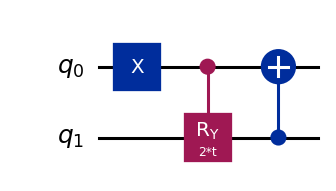

energy of the Hartree-Fock state (t = 0): -1.836968 Hartree (electronic), -1.116999 (total)
max |circuit - NumPy| over the sweep: 6.7e-16
correlation energy E_exact - E_HF = -0.020307 Hartree = -12.7 kcal/mol


In [7]:
t = Parameter("t")
ansatz_toy = QuantumCircuit(2)
ansatz_toy.x(0)                 # Hartree-Fock state |01>
ansatz_toy.cry(2 * t, 0, 1)     # controlled-RY(2t): control qubit 0, target qubit 1
ansatz_toy.cx(1, 0)             # CNOT: control qubit 1, target qubit 0   ->  cos t |01> + sin t |10>
try:
    fig = ansatz_toy.draw("mpl"); display(fig); plt.close(fig)
except Exception:
    print(ansatz_toy.draw("text"))

estimator = StatevectorEstimator()                                   # exact expectation values (no sampling noise)

def energy(params, op=H_toy, circuit=ansatz_toy, est=estimator):
    """<psi(params)| op |psi(params)> estimated with the primitive `est`."""
    pub = (circuit, op, np.atleast_1d(np.asarray(params, dtype=float)))
    return float(np.real(est.run([pub]).result()[0].data.evs))

# cross-check the circuit against a plain NumPy calculation with the state cos t |01> + sin t |10>
def energy_numpy(tv):
    psi = np.array([0, np.cos(tv), np.sin(tv), 0.0])
    return float(psi @ H_toy.to_matrix().real @ psi)

tt = np.linspace(-1.0, 1.0, 201)
sweep = estimator.run([(ansatz_toy, H_toy, tt.reshape(-1, 1))]).result()[0].data.evs      # all 201 angles in one call
E_hf = energy([0.0])
print(f"energy of the Hartree-Fock state (t = 0): {E_hf:.6f} Hartree (electronic), {E_hf + E_NUC_TOY:.6f} (total)")
print(f"max |circuit - NumPy| over the sweep: {np.max(np.abs(sweep - np.array([energy_numpy(x) for x in tt]))):.1e}")
print(f"correlation energy E_exact - E_HF = {eigenvalues_toy[0] - E_hf:.6f} Hartree = {(eigenvalues_toy[0] - E_hf) * HARTREE_TO_KCAL:.1f} kcal/mol")

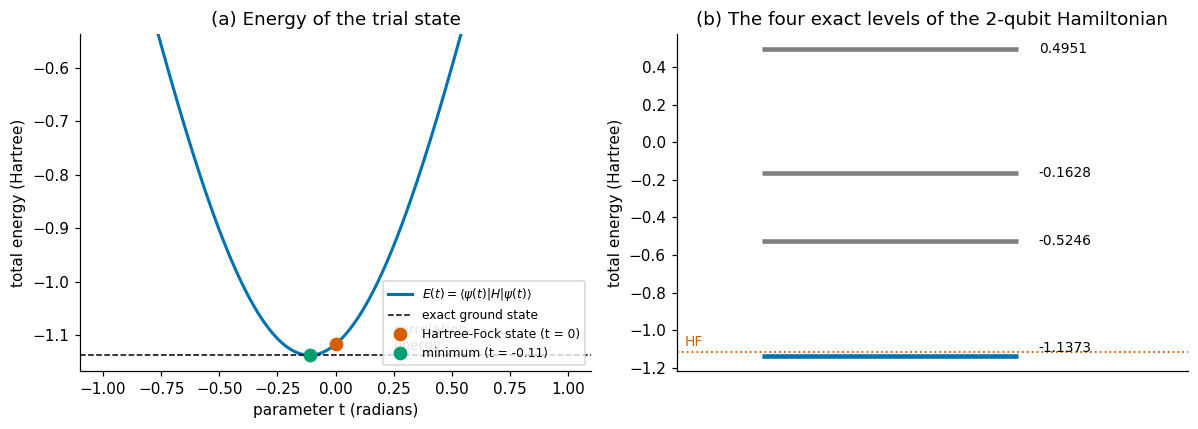

In [8]:
#@title Figure 2: the variational principle for H2 { display-mode: "form" }
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
t_star = tt[np.argmin(sweep)]
ax[0].plot(tt, sweep + E_NUC_TOY, color=COLORS["blue"], lw=2, label=r"$E(t)=\langle\psi(t)|H|\psi(t)\rangle$")
ax[0].axhline(eigenvalues_toy[0] + E_NUC_TOY, color="k", ls="--", lw=1, label="exact ground state")
ax[0].plot([0], [E_hf + E_NUC_TOY], "o", color=COLORS["red"], ms=8, label="Hartree-Fock state (t = 0)")
ax[0].plot([t_star], [sweep.min() + E_NUC_TOY], "o", color=COLORS["green"], ms=8, label=f"minimum (t = {t_star:.2f})")
ax[0].annotate("correlation\nenergy", xy=(0.25, 0.5 * (E_hf + eigenvalues_toy[0]) + E_NUC_TOY), fontsize=9, color=COLORS["gray"], ha="left")
ax[0].set(xlabel="parameter t (radians)", ylabel="total energy (Hartree)", ylim=(eigenvalues_toy[0] + E_NUC_TOY - 0.03, eigenvalues_toy[0] + E_NUC_TOY + 0.6),
          title="(a) Energy of the trial state"); ax[0].legend(fontsize=8)
lev = eigenvalues_toy + E_NUC_TOY
for k, e in enumerate(lev):
    ax[1].hlines(e, 0.2, 0.8, color=COLORS["blue"] if k == 0 else COLORS["gray"], lw=3)
    ax[1].text(0.85, e + (0.04 if k == 0 else 0), f"{e:.4f}", va="center", fontsize=9)
ax[1].axhline(E_hf + E_NUC_TOY, color=COLORS["red"], ls=":", lw=1.2); ax[1].text(0.02, E_hf + E_NUC_TOY + 0.03, "HF", color=COLORS["red"], fontsize=9)
ax[1].set(xlim=(0, 1.2), xticks=[], ylabel="total energy (Hartree)", title="(b) The four exact levels of the 2-qubit Hamiltonian")
plt.tight_layout(); plt.show()

**Figure 2.** (a) The energy of the trial state $|\psi(t)\rangle$ as a function of the parameter: it is never below the exact ground-state energy (dashed line), which is the *variational principle*. The Hartree-Fock state ($t=0$, red) lies above the exact energy by the correlation energy (about $-0.0203$ Hartree, or $-12.7$ kcal/mol, in the units of the calculation above), and the minimum (green) touches the exact ground state because our one-parameter family contains it. (b) The four exact energy levels (ground state, a triplet and two excited singlets).

### 4.2 VQE in a few lines
All the parts of VQE are now in place: an ansatz (the circuit), an estimator (computes $E(t)$), and a classical optimiser. We use SciPy's COBYLA optimiser and start at $t=0$ (the HF state).

In [9]:
trace = []                                                           # record the energy at every evaluation
def objective(x):
    e = energy(x)
    trace.append(e)
    return e

result_toy = minimize(objective, x0=[0.0], method="COBYLA", tol=1e-8)
print(f"VQE energy     : {result_toy.fun:.8f} Hartree (electronic)")
print(f"exact energy   : {eigenvalues_toy[0]:.8f} Hartree (electronic)")
print(f"error          : {abs(result_toy.fun - eigenvalues_toy[0]):.1e} Hartree   (chemical accuracy is {CHEMICAL_ACCURACY:.1e})")
print(f"optimal t      : {result_toy.x[0]:.4f} rad | energy evaluations: {len(trace)}")

VQE energy     : -1.85727503 Hartree (electronic)
exact energy   : -1.85727503 Hartree (electronic)
error          : 8.9e-16 Hartree   (chemical accuracy is 1.6e-03)
optimal t      : -0.1118 rad | energy evaluations: 43


The optimiser found the exact ground-state energy in a few dozen evaluations. For this tiny problem VQE has no advantage over exact diagonalisation: the point of the exercise is to see that **every ingredient is simple**. The real-world difficulty (and the real promise) lies in the *size* of the problem: for a larger molecule the Hamiltonian has many more Pauli terms, the trial states cannot be handled classically, and each energy must be estimated from a finite number of measurements (Section 7).

## 5. The Qiskit Nature pipeline, step by step

Now we derive the Hamiltonian from the molecule itself, with Qiskit Nature and PySCF, and check each step against what we know.

### 5.1 The driver and the problem
The `PySCFDriver` runs the classical chemistry calculation: it builds the STO-3G basis, solves the Hartree-Fock equations, and transforms the integrals to the molecular-orbital basis. `driver.run()` packages the result in an **`ElectronicStructureProblem`**.

In [10]:
driver = PySCFDriver(atom=f"H 0.0 0.0 0.0; H 0.0 0.0 {BOND_LENGTH}", basis=BASIS, unit=DistanceUnit.ANGSTROM)
problem = driver.run()

n_alpha, n_beta = problem.num_particles
print(f"number of electrons (alpha, beta)   : ({n_alpha}, {n_beta})")
print(f"number of spatial orbitals           : {problem.num_spatial_orbitals}   -> spin orbitals: {2 * problem.num_spatial_orbitals}")
E_nuc = problem.hamiltonian.nuclear_repulsion_energy
print(f"nuclear repulsion energy             : {E_nuc:.6f} Hartree   (analytic 1/R: {1 / (BOND_LENGTH * BOHR_PER_ANGSTROM):.6f})")

def hf_energy(R, basis=BASIS):
    """Total Hartree-Fock energy of H2 at bond length R (Angstrom), computed directly with PySCF."""
    mol = gto.M(atom=f"H 0 0 0; H 0 0 {R}", basis=basis, unit="Angstrom", verbose=0)
    return float(scf.RHF(mol).run().e_tot)
E_hf_total = hf_energy(BOND_LENGTH)
print(f"Hartree-Fock total energy (PySCF)    : {E_hf_total:.6f} Hartree")
try:
    one_body = np.asarray(problem.hamiltonian.electronic_integrals.alpha["+-"])
    print("\none-electron integrals h_pq in the molecular-orbital basis (Hartree):\n", np.round(one_body, 4))
except Exception as err:
    print("(the integrals are stored in problem.hamiltonian.electronic_integrals)", err)

number of electrons (alpha, beta)   : (1, 1)
number of spatial orbitals           : 2   -> spin orbitals: 4
nuclear repulsion energy             : 0.719969 Hartree   (analytic 1/R: 0.719969)
Hartree-Fock total energy (PySCF)    : -1.116999 Hartree

one-electron integrals h_pq in the molecular-orbital basis (Hartree):
 [[-1.2563 -0.    ]
 [-0.     -0.4719]]


The problem knows the number of electrons and orbitals, the nuclear repulsion energy (equal to $1/R$, as we computed in Section 3.4), and the Hamiltonian integrals. It also carries the operators of some **properties** (particle number, spin, dipole moment) that we will meet in the final output.

### 5.2 The second-quantized Hamiltonian
`problem.hamiltonian.second_q_op()` assembles the fermionic operator of Section 2.2 from the integrals. Each term is a product of creation (`+_p`) and annihilation (`-_p`) operators on the four spin orbitals $p=0,\dots,3$ (the two $\alpha$ orbitals first, then the two $\beta$ orbitals).

In [11]:
fermionic_op = problem.hamiltonian.second_q_op()
print("number of terms in the fermionic operator:", len(fermionic_op))
print("\nfirst lines of the operator:")
print("\n".join(str(fermionic_op).splitlines()[:8]))

number of terms in the fermionic operator: 36

first lines of the operator:
Fermionic Operator
number spin orbitals=4, number terms=36
  -1.2563390730032498 * ( +_0 -_0 )
+ -0.47189600728114184 * ( +_1 -_1 )
+ -1.2563390730032498 * ( +_2 -_2 )
+ -0.47189600728114184 * ( +_3 -_3 )
+ 0.33785507740175813 * ( +_0 +_0 -_0 -_0 )
+ 0.3322908651276482 * ( +_0 +_1 -_1 -_0 )


### 5.3 Mapping to qubits, and what the reduction saves
Now the **mappers** of Section 2.3. We map the same fermionic operator four ways and compare the number of qubits and the number of Pauli strings. `ParityMapper(num_particles=...)` also performs the two-qubit reduction (it needs to know the numbers of $\alpha$ and $\beta$ electrons to fix the conserved parities).

In [12]:
mappers = {"Jordan-Wigner": JordanWignerMapper(),
           "Bravyi-Kitaev": BravyiKitaevMapper(),
           "Parity": ParityMapper(),
           "Parity + 2-qubit reduction": ParityMapper(num_particles=problem.num_particles)}
qubit_ops = {name: m.map(fermionic_op).simplify() for name, m in mappers.items()}

rows = []
for name, op in qubit_ops.items():
    rows.append((name, op.num_qubits, len(op), 2 ** op.num_qubits))
display(pd.DataFrame(rows, columns=["mapper", "qubits", "Pauli strings", "dimension of the state space"]))

qubit_op = qubit_ops["Parity + 2-qubit reduction"]
print("\nthe reduced qubit Hamiltonian:")
print(qubit_op)

,mapper,qubits,Pauli strings,dimension of the state space
0,Jordan-Wigner,4,15,16
1,Bravyi-Kitaev,4,15,16
2,Parity,4,15,16
3,Parity + 2-qubit reduction,2,5,4



the reduced qubit Hamiltonian:
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])


**Table 1.** All four mappings describe the *same* physics. The Jordan-Wigner, Bravyi-Kitaev and parity encodings use 4 qubits; the parity encoding with the two-qubit reduction uses only **2 qubits** and a handful of Pauli strings. Compare the reduced operator with the five-term Hamiltonian of Section 4 (the qubit ordering and signs of individual terms can differ; the spectrum must be the same).

### 5.4 Exact diagonalisation as a check
Because the operator is small we can diagonalise it exactly with NumPy. The reduced operator acts on the 4-dimensional space of the two-electron states with one $\alpha$ and one $\beta$ electron, so its four eigenvalues are the four levels of Figure 2(b).

In [13]:
eig_reduced = np.linalg.eigvalsh(qubit_op.to_matrix())
print("eigenvalues of the reduced (2-qubit) operator :", np.round(eig_reduced, 6))
eig_full = np.linalg.eigvalsh(qubit_ops["Jordan-Wigner"].to_matrix())
print("lowest eigenvalues of the 4-qubit JW operator :", np.round(eig_full[:4], 6), " (the whole Fock space, 0 to 4 electrons)")
print(f"\nexact ground state: electronic {eig_reduced[0]:.6f} + nuclear repulsion {E_nuc:.6f} = total {eig_reduced[0] + E_nuc:.6f} Hartree")
if abs(BOND_LENGTH - 0.735) < 1e-9:
    print(f"difference to the five-term Hamiltonian of Section 4 (all four eigenvalues): {np.max(np.abs(eig_reduced - eigenvalues_toy)):.1e} Hartree")

eigenvalues of the reduced (2-qubit) operator : [-1.857275 -1.244585 -0.882722 -0.224911]
lowest eigenvalues of the 4-qubit JW operator : [-1.857275 -1.256339 -1.256339 -1.244585]  (the whole Fock space, 0 to 4 electrons)

exact ground state: electronic -1.857275 + nuclear repulsion 0.719969 = total -1.137306 Hartree
difference to the five-term Hamiltonian of Section 4 (all four eigenvalues): 2.8e-15 Hartree


The derived operator has the same spectrum as the literature Hamiltonian of Section 4 (the difference is at the level of the numerical precision of the quoted coefficients), so the pipeline `PySCF → fermionic operator → parity mapping → reduction` indeed reproduces the two-qubit Hamiltonian from first principles. The 4-qubit operator acts on the whole Fock space, with states of 0 to 4 electrons; Qiskit Nature takes care to select the sector with the right number of electrons, which the two-qubit reduction does automatically.

### 5.5 The ansatz: Hartree-Fock state plus UCCSD
The two ingredients of Section 2.4: the **Hartree-Fock initial state** (a basis state of the qubits, expressed in the parity encoding) and the **UCCSD** excitation operators, translated to circuits by the same mapper.

ansatz: 2 qubits, 3 variational parameters
parameters: ['t[0]', 't[1]', 't[2]']


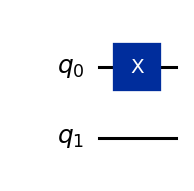

In [14]:
mapper = ParityMapper(num_particles=problem.num_particles)             # parity mapping with the 2-qubit reduction
init_state = HartreeFock(problem.num_spatial_orbitals, problem.num_particles, mapper)
ansatz = UCCSD(problem.num_spatial_orbitals, problem.num_particles, mapper, initial_state=init_state)

print(f"ansatz: {ansatz.num_qubits} qubits, {ansatz.num_parameters} variational parameters")
print("parameters:", [p.name for p in ansatz.parameters])
try:
    fig = init_state.draw("mpl"); display(fig); plt.close(fig)
except Exception:
    print(init_state.draw("text"))

The ansatz acts on **2 qubits** (the same number as the reduced Hamiltonian) and has a small number of parameters: the amplitudes of the single and double excitations of the two electrons between the two spatial orbitals. The drawing above shows the HF initial state, the first part of the circuit.

### 5.6 Running VQE
We now assemble the variational quantum eigensolver of `qiskit_algorithms`: the estimator primitive (`StatevectorEstimator`, which computes expectation values exactly), the UCCSD ansatz, and the L-BFGS-B optimiser. We start the optimisation at **all-zero parameters**, which is the Hartree-Fock state (Section 2.4), and record the energy at every evaluation with a *callback*. The `GroundStateEigensolver` ties the mapper and the VQE together and also evaluates the other properties.

In [15]:
history = {"evals": [], "energy": []}
def callback(eval_count, parameters, mean, metadata):
    history["evals"].append(eval_count)
    history["energy"].append(float(np.real(mean)))

vqe = VQE(StatevectorEstimator(), ansatz, L_BFGS_B(), callback=callback)
vqe.initial_point = np.zeros(ansatz.num_parameters)                     # all zeros = the Hartree-Fock state

algorithm = GroundStateEigensolver(mapper, vqe)
t0 = time.perf_counter()
result = algorithm.solve(problem)
print(f"VQE finished in {time.perf_counter() - t0:.1f} s, {len(history['energy'])} energy evaluations")
result.formatting_precision = 6
print(result)

/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


VQE finished in 1.5 s, 20 energy evaluations
=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -1.857275
  - computed part:      -1.857275
~ Nuclear repulsion energy (Hartree): 0.719969
> Total ground state energy (Hartree): -1.137306
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  1.388949]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  1.388949]
    - computed part:      [0.0  0.0  1.388949]
  > Dipole moment (a.u.): [0.0  0.0  0.0]  Total: 0.0
                 (debye): [0.0  0.0  0.0]  Total: 0.0
 


### 5.7 Reading the output
The printed result has three parts:

* **GROUND STATE ENERGY.** The *electronic* ground-state energy (the lowest eigenvalue of the qubit Hamiltonian, as found by VQE), the *nuclear repulsion energy* (the constant $1/R$), and their sum, the **total ground-state energy**: this is the number a chemist compares with experiment or with other methods.
* **MEASURED OBSERVABLES.** Properties of the computed state, measured with the same circuit: the number of particles (2), the total spin $S$, $S^2$ and the magnetisation $M$. For the ground state of H₂ they are 2, 0, 0 and 0: a spin-singlet with two electrons, as expected. (If VQE had converged to an excited state or a state with the wrong number of electrons, this section would show it.)
* **DIPOLE MOMENTS.** The electric dipole moment has a nuclear and an electronic part, each of which depends on the choice of origin (the nuclei are placed on the $z$ axis). Their sum, the physical dipole moment of the molecule, is **zero** for a homonuclear diatomic molecule by symmetry, which is a nice consistency check.

### 5.8 Validation: is VQE right?
A result is only worth something if it is verified. We compare three numbers: the **Hartree-Fock** energy (computed directly with PySCF), the **VQE** energy, and the **exact** ground-state energy (the same Qiskit Nature pipeline, but with the classical `NumPyMinimumEigensolver`, which diagonalises the qubit operator exactly). The *correlation energy* is the difference between exact and HF.

In [16]:
exact_result = GroundStateEigensolver(mapper, NumPyMinimumEigensolver()).solve(problem)

def total_energy(res):
    try:
        return float(np.real(res.total_energies[0]))
    except Exception:                                                    # fallback: electronic eigenvalue + nuclear repulsion
        return float(np.real(res.eigenvalues[0])) + E_nuc
E_vqe, E_exact = total_energy(result), total_energy(exact_result)

table = pd.DataFrame({"method": ["Hartree-Fock (PySCF)", "VQE (UCCSD, StatevectorEstimator)", "exact (diagonalisation)"],
                      "total energy (Hartree)": [E_hf_total, E_vqe, E_exact],
                      "error vs exact (mHa)": [1e3 * (E_hf_total - E_exact), 1e3 * (E_vqe - E_exact), 0.0]})
display(table.round(6))
corr = E_exact - E_hf_total
print(f"\ncorrelation energy (exact - HF): {corr:.6f} Hartree = {corr * HARTREE_TO_KCAL:.2f} kcal/mol")
print(f"fraction of the correlation energy recovered by VQE: {100 * (E_vqe - E_hf_total) / corr:.4f} %")
print(f"VQE error is {'below' if abs(E_vqe - E_exact) < CHEMICAL_ACCURACY else 'above'} chemical accuracy ({CHEMICAL_ACCURACY * 1e3:.2f} mHa)")

,method,total energy (Hartree),error vs exact (mHa)
0,Hartree-Fock (PySCF),-1.116999,20.307039
1,"VQE (UCCSD, StatevectorEstimator)",-1.137306,0.000000
2,exact (diagonalisation),-1.137306,0.000000



correlation energy (exact - HF): -0.020307 Hartree = -12.74 kcal/mol
fraction of the correlation energy recovered by VQE: 100.0000 %
VQE error is below chemical accuracy (1.59 mHa)


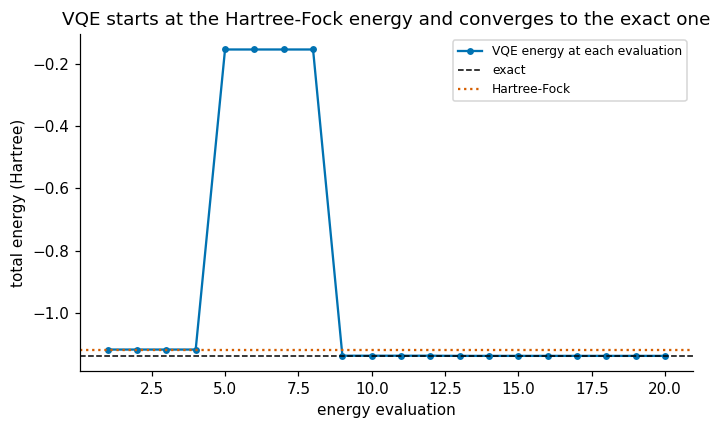

In [17]:
#@title Figure 3: convergence of VQE { display-mode: "form" }
fig, ax = plt.subplots(figsize=(6.5, 4))
e_total = np.array(history["energy"]) + E_nuc
ax.plot(history["evals"], e_total, "o-", ms=3.5, color=COLORS["blue"], label="VQE energy at each evaluation")
ax.axhline(E_exact, color="k", ls="--", lw=1, label="exact")
ax.axhline(E_hf_total, color=COLORS["red"], ls=":", lw=1.5, label="Hartree-Fock")
ax.set(xlabel="energy evaluation", ylabel="total energy (Hartree)", title="VQE starts at the Hartree-Fock energy and converges to the exact one")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 3.** The energy at each evaluation of the optimiser. The first evaluation (all parameters zero) reproduces the Hartree-Fock energy; the optimiser then lowers the energy until it reaches the exact ground-state energy. (The L-BFGS-B optimiser estimates gradients by finite differences, so each iteration uses several evaluations.)

### 5.9 What does the energy landscape look like?
The energy $E(\boldsymbol\theta)$ is a function of the ansatz parameters. We can look at it, because with the exact estimator it is cheap: we vary **one parameter at a time**, with the others at zero (the HF point), and plot the total energy.

/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


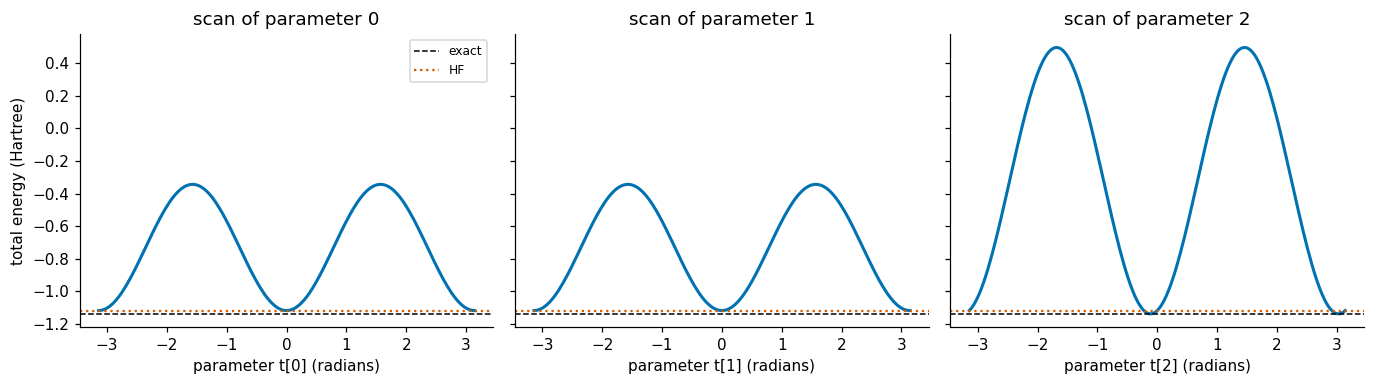

In [18]:
grid = np.linspace(-np.pi, np.pi, 181)
n_par = ansatz.num_parameters
fig, axes = plt.subplots(1, n_par, figsize=(4.2 * n_par, 3.6), sharey=True)
axes = np.atleast_1d(axes)
est_exact = StatevectorEstimator()
for k, a in enumerate(axes):
    params = np.zeros((len(grid), n_par)); params[:, k] = grid                  # scan parameter k, the others stay at 0
    scan = np.real(est_exact.run([(ansatz, qubit_op, params)]).result()[0].data.evs) + E_nuc
    a.plot(grid, scan, color=COLORS["blue"], lw=2)
    a.axhline(E_exact, color="k", ls="--", lw=1, label="exact"); a.axhline(E_hf_total, color=COLORS["red"], ls=":", lw=1.5, label="HF")
    a.set(xlabel=f"parameter {ansatz.parameters[k].name} (radians)", title=f"scan of parameter {k}")
axes[0].set_ylabel("total energy (Hartree)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 4.** The total energy along each parameter direction, with the other parameters at zero. At the origin (all parameters zero) the energy equals the Hartree-Fock energy (dotted red line). Look at which parameters can **lower** the energy below the HF value, and which only raise it. By Brillouin's theorem the HF energy is stationary with respect to single excitations (the curves for the parameters that correspond to single excitations are flat to first order at the origin), so the energy can only be lowered by the **double excitation**, which brings in the $\sigma_u^2$ configuration. The minimum of that curve reaches the exact energy (dashed line).

## 6. The potential energy curve of H₂

So far we studied one geometry. A chemist wants the whole curve $E(R)$: it shows the equilibrium bond length (the minimum) and how the bond breaks. For every bond length we run the full pipeline (driver, mapper, VQE) and compare VQE with the exact result and with Hartree-Fock. To save time, each VQE starts from the optimal parameters of the previous (slightly shorter) bond length, a standard "warm start".

In [19]:
distances = [0.3, 0.4, 0.5, 0.6, 0.7, 0.735, 0.8, 0.9, 1.0, 1.2, 1.5, 1.8, 2.1, 2.5]     # Angstrom, increasing order

def solve_at(R, initial_point=None):
    """Full pipeline at bond length R: returns (E_vqe, E_exact, E_hf, optimal parameters)."""
    prob = PySCFDriver(atom=f"H 0.0 0.0 0.0; H 0.0 0.0 {R}", basis=BASIS, unit=DistanceUnit.ANGSTROM).run()
    mp = ParityMapper(num_particles=prob.num_particles)
    ans = UCCSD(prob.num_spatial_orbitals, prob.num_particles, mp,
                initial_state=HartreeFock(prob.num_spatial_orbitals, prob.num_particles, mp))
    solver = VQE(StatevectorEstimator(), ans, L_BFGS_B())
    solver.initial_point = np.zeros(ans.num_parameters) if initial_point is None else initial_point
    res = GroundStateEigensolver(mp, solver).solve(prob)
    exact = GroundStateEigensolver(mp, NumPyMinimumEigensolver()).solve(prob)
    return total_energy(res), total_energy(exact), hf_energy(R), np.asarray(res.raw_result.optimal_point)

pes = []; point = None; t0 = time.perf_counter()
for R in distances:
    e_v, e_x, e_h, point = solve_at(R, point)
    pes.append((R, e_h, e_v, e_x))
    print(f"R = {R:5.3f} A | HF {e_h:10.6f} | VQE {e_v:10.6f} | exact {e_x:10.6f} | VQE error {1e3 * (e_v - e_x):8.4f} mHa")
print(f"done in {time.perf_counter() - t0:.0f} s")
pes = np.array(pes)

R = 0.300 A | HF  -0.593828 | VQE  -0.601804 | exact  -0.601804 | VQE error   0.0000 mHa
R = 0.400 A | HF  -0.904361 | VQE  -0.914150 | exact  -0.914150 | VQE error   0.0000 mHa
R = 0.500 A | HF  -1.042996 | VQE  -1.055160 | exact  -1.055160 | VQE error   0.0000 mHa
R = 0.600 A | HF  -1.101128 | VQE  -1.116286 | exact  -1.116286 | VQE error   0.0000 mHa
R = 0.700 A | HF  -1.117349 | VQE  -1.136189 | exact  -1.136189 | VQE error   0.0000 mHa
R = 0.735 A | HF  -1.116999 | VQE  -1.137306 | exact  -1.137306 | VQE error   0.0000 mHa
R = 0.800 A | HF  -1.110850 | VQE  -1.134148 | exact  -1.134148 | VQE error   0.0000 mHa
R = 0.900 A | HF  -1.091914 | VQE  -1.120560 | exact  -1.120560 | VQE error   0.0000 mHa
R = 1.000 A | HF  -1.066109 | VQE  -1.101150 | exact  -1.101150 | VQE error   0.0000 mHa
R = 1.200 A | HF  -1.005107 | VQE  -1.056741 | exact  -1.056741 | VQE error   0.0000 mHa
R = 1.500 A | HF  -0.910874 | VQE  -0.998149 | exact  -0.998149 | VQE error   0.0000 mHa
R = 1.800 A | HF  -0.

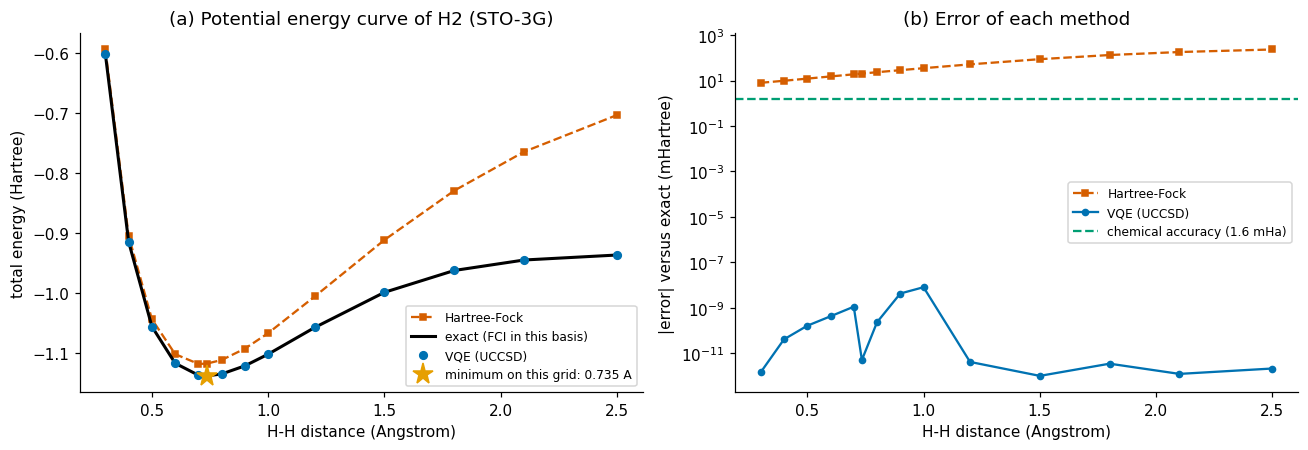

In [20]:
#@title Figure 5: the potential energy curve of H2 { display-mode: "form" }
R, e_hf, e_vqe, e_ex = pes.T
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(R, e_hf, "s--", ms=4, color=COLORS["red"], label="Hartree-Fock")
ax[0].plot(R, e_ex, "-", lw=2, color="k", label="exact (FCI in this basis)")
ax[0].plot(R, e_vqe, "o", ms=5, color=COLORS["blue"], label="VQE (UCCSD)")
i_min = int(np.argmin(e_ex))
ax[0].plot([R[i_min]], [e_ex[i_min]], "*", ms=14, color=COLORS["orange"], label=f"minimum on this grid: {R[i_min]:.3f} A")
ax[0].set(xlabel="H-H distance (Angstrom)", ylabel="total energy (Hartree)", title="(a) Potential energy curve of H2 (STO-3G)"); ax[0].legend(fontsize=8)
ax[1].semilogy(R, np.abs(e_hf - e_ex) * 1e3 + 1e-12, "s--", ms=4, color=COLORS["red"], label="Hartree-Fock")
ax[1].semilogy(R, np.abs(e_vqe - e_ex) * 1e3 + 1e-12, "o-", ms=4, color=COLORS["blue"], label="VQE (UCCSD)")
ax[1].axhline(CHEMICAL_ACCURACY * 1e3, color=COLORS["green"], ls="--", lw=1.5, label="chemical accuracy (1.6 mHa)")
ax[1].set(xlabel="H-H distance (Angstrom)", ylabel="|error| versus exact (mHartree)", title="(b) Error of each method"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 5.** (a) The potential energy curve of H₂ in the STO-3G basis. Hartree-Fock (red) is reasonable near the equilibrium geometry but **rises above the exact curve** as the bond is stretched, whereas VQE (blue points) follows the exact curve (black). (b) The error with respect to the exact result on a logarithmic scale: the Hartree-Fock error grows with the distance, while the VQE error stays below chemical accuracy (green line) wherever the optimisation converged. (The VQE error is the *optimisation* error: a VQE with a good ansatz can only fall short of the exact result if the optimiser stops early or gets stuck.)

**Why does Hartree-Fock fail at large distance?** Restricted Hartree-Fock forces both electrons into the same bonding orbital $\sigma_g$, which at large separation describes an equal mixture of "H$^+$ H$^-$" (ionic) and "H H" (covalent) configurations; the ionic part is energetically wrong. The exact wave function mixes in the $\sigma_u^2$ configuration, with a weight that grows with the distance, in such a way that the ionic parts cancel. This *static correlation* is invisible to a single-determinant method, and is where multi-configurational methods, and quantum algorithms, are needed.

## 7. Measurement noise and chemical accuracy

Our estimator so far computed expectation values **exactly**. On a quantum computer every term $\langle P_k\rangle$ must be *estimated* by repeating the circuit many times (shots), so each energy has a **statistical error** that decreases only as $1/\sqrt{\text{shots}}$: halving it costs four times as many shots. How precise must the energy be for VQE to reach chemical accuracy? We test it on the one-parameter ansatz of Section 4. The `StatevectorEstimator` can emulate sampling: with `default_precision=p` every estimated energy carries a random error of typical size $p$ (in Hartree). We optimise the parameter (with COBYLA, which tolerates noise reasonably well) for several values of $p$, repeat each optimisation `N_REPEATS` times, and in the end evaluate the **exact** energy of the optimised parameter.

In [21]:
precisions = [0.1, 0.03, 0.01, 0.003, 0.001, 0.0003]
est_clean = StatevectorEstimator()
results_noise = {}
t0 = time.perf_counter()
for p in precisions:
    errors = []
    for rep in range(N_REPEATS):
        est_noisy = StatevectorEstimator(default_precision=p, seed=SEED + 1000 * rep + 17)
        r = minimize(lambda x: energy(x, est=est_noisy), x0=[0.0], method="COBYLA", options=dict(maxiter=60, rhobeg=0.3))
        errors.append(energy(r.x, est=est_clean) - eigenvalues_toy[0])           # EXACT energy of the optimised parameter, minus exact ground state
    results_noise[p] = np.array(errors)
    print(f"precision {p:7.4f} Hartree | mean error {1e3 * results_noise[p].mean():8.3f} mHa | within chemical accuracy: {100 * np.mean(results_noise[p] < CHEMICAL_ACCURACY):5.1f} % of runs")
print(f"done in {time.perf_counter() - t0:.0f} s")

precision  0.1000 Hartree | mean error    0.000 mHa | within chemical accuracy: 100.0 % of runs
precision  0.0300 Hartree | mean error    0.000 mHa | within chemical accuracy: 100.0 % of runs
precision  0.0100 Hartree | mean error    0.000 mHa | within chemical accuracy: 100.0 % of runs
precision  0.0030 Hartree | mean error    0.000 mHa | within chemical accuracy: 100.0 % of runs
precision  0.0010 Hartree | mean error    0.000 mHa | within chemical accuracy: 100.0 % of runs
precision  0.0003 Hartree | mean error    0.000 mHa | within chemical accuracy: 100.0 % of runs
done in 13 s


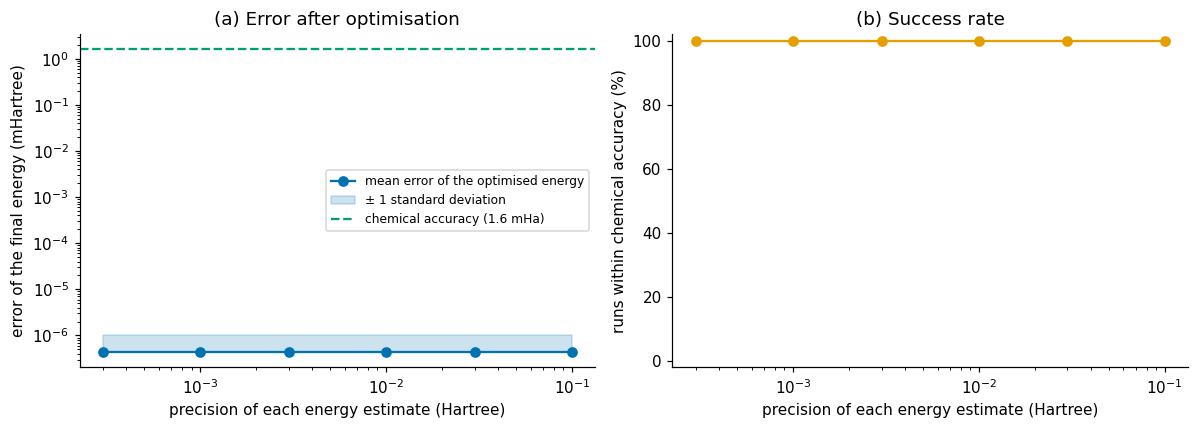

In [22]:
#@title Figure 6: how precise must the measurements be? { display-mode: "form" }
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mean_err = np.array([1e3 * results_noise[p].mean() for p in precisions])
spread = np.array([1e3 * results_noise[p].std() for p in precisions])
ax[0].loglog(precisions, mean_err, "o-", color=COLORS["blue"], label="mean error of the optimised energy")
ax[0].fill_between(precisions, np.maximum(mean_err - spread, 1e-6), mean_err + spread, color=COLORS["blue"], alpha=0.2, label="± 1 standard deviation")
ax[0].axhline(CHEMICAL_ACCURACY * 1e3, color=COLORS["green"], ls="--", lw=1.5, label="chemical accuracy (1.6 mHa)")
ax[0].set(xlabel="precision of each energy estimate (Hartree)", ylabel="error of the final energy (mHartree)", title="(a) Error after optimisation"); ax[0].legend(fontsize=8)
ax[1].semilogx(precisions, [100 * np.mean(results_noise[p] < CHEMICAL_ACCURACY) for p in precisions], "o-", color=COLORS["orange"])
ax[1].set(xlabel="precision of each energy estimate (Hartree)", ylabel="runs within chemical accuracy (%)", title="(b) Success rate", ylim=(-2, 102))
plt.tight_layout(); plt.show()

**Figure 6.** (a) The error of the optimised energy (with its spread over the repeated runs) against the precision of each energy estimate, with chemical accuracy as the green line. The larger the noise in the objective, the less well the optimiser can locate the minimum, and the energy error grows with it. (b) The fraction of runs that reached chemical accuracy: it rises toward 100 % only when each energy is estimated to about a **milli-Hartree**. Because the precision scales as $1/\sqrt{\text{shots}}$, reaching it needs a very large number of shots per energy evaluation, and a real VQE needs many evaluations: this is one of the central practical obstacles of quantum chemistry on near-term hardware (and one reason why error mitigation, clever measurement strategies and better optimisers are active research areas).

## 8. What now?

* **What we did.** We computed the ground-state energy and properties of H₂ on a (simulated) quantum computer, and we verified it against exact results at every step. The pipeline (driver → fermionic operator → mapper → ansatz → VQE → properties) is the same for any molecule that a driver can handle.
* **What changes for larger molecules.** The number of spin orbitals (hence qubits) grows with the size of the molecule and of the basis; the number of Pauli strings in $H$ grows roughly as the fourth power of the number of orbitals; the ansatz becomes deeper; and the measurement budget of Section 7 grows with it. Tools such as the `ActiveSpaceTransformer` and `FreezeCoreTransformer` of Qiskit Nature reduce the problem to the chemically important orbitals.
* **Simulator or hardware?** The `StatevectorEstimator` is a classical simulator of the quantum computer. The same circuits can be run on real hardware by exchanging the estimator for one provided by a hardware service; the noise of the device then adds to the statistical error that we studied.
* **Beyond the ground state.** Qiskit Nature also provides excited-state algorithms (for example qEOM), other mappers and ansätze, and vibrational and lattice-model problems; see the Qiskit Nature tutorials.

### Check your understanding
1. How many spin orbitals, qubits (Jordan-Wigner) and qubits (parity with reduction) does H₂ in the STO-3G basis need? What is the dimension of the state space in each case?
2. Why is the energy of the trial state $|\psi(t)\rangle$ never below the exact ground-state energy?
3. Why do we start the UCCSD optimisation at $\boldsymbol\theta=0$?
4. What is the correlation energy, and why does Hartree-Fock miss it?
5. Which number must be small for VQE to be useful for chemistry, and what limits it in a real device?

<details><summary>Answers</summary>

1. 2 spatial orbitals give 4 spin orbitals. Jordan-Wigner uses 4 qubits (state space of dimension $2^4=16$); the parity mapping with two-qubit reduction uses 2 qubits (dimension 4: the two-electron states with one $\alpha$ and one $\beta$ electron).
2. The variational principle: for any normalised state the energy is a weighted average of the eigenvalues of $H$, hence at least the lowest one.
3. With all parameters zero the circuit prepares the Hartree-Fock state, the best single-configuration approximation, which is already close to the exact ground state: the optimiser starts in the right basin.
4. It is the difference between the exact (FCI) energy and the Hartree-Fock energy (about $-0.020$ Hartree for H₂ at 0.735 Å). Hartree-Fock describes the electrons with one configuration (both in $\sigma_g$), while the exact state also contains the doubly excited configuration.
5. The energy error must be below chemical accuracy (1.6 mHartree). In a real device it is limited by the statistical error of the finite number of measurements (decreasing as $1/\sqrt{\text{shots}}$) and by hardware noise.
</details>

### Exercises
1. **Equilibrium bond length.** Refine the grid of Section 6 near the minimum and estimate the equilibrium bond length and the bond energy (the energy difference to the separated atoms, which you can obtain from `hf_energy` of a single H atom or from the large-distance limit).
2. **Other basis sets.** Set `BASIS = "631g"`. How many qubits does the problem need now before and after the two-qubit reduction? Is the VQE still below chemical accuracy?
3. **Another ansatz.** Replace UCCSD by a hardware-efficient ansatz (for example `TwoLocal(2, ["ry", "rz"], "cz", reps=2)` composed after the Hartree-Fock circuit). How many parameters does it have, and does the optimiser find the exact energy?
4. **Other mappers.** Run the pipeline with the Jordan-Wigner mapper (4 qubits). What changes in the ansatz and in the cost?
5. **Another molecule.** Try LiH (for example `Li 0 0 0; H 0 0 1.6`) with the `ActiveSpaceTransformer` to keep 2 electrons in 2 orbitals. How do the qubit count and the correlation energy compare with H₂?
6. **Measurement budget.** The statistical error of an energy estimate is $\sqrt{\sum_k c_k^2\,\mathrm{Var}(P_k)/\text{shots}_k}$. Estimate the number of shots per energy evaluation for chemical accuracy at the HF point of H₂.

### Troubleshooting

| Symptom | What to do |
|---|---|
| `ModuleNotFoundError` for `qiskit_nature`, `qiskit_algorithms` or `pyscf` right after the install | Run the install cell again and restart the session if Colab asks you to. |
| The installation of PySCF takes a long time or fails | Re-run the cell; PySCF is a large package. Wheels are available for current Colab runtimes. |
| `ImportError: cannot import name ...` from `qiskit_nature` | The notebook targets the `second_q` interface of Qiskit Nature 0.7 and later. The old `qiskit_nature.drivers` and `QubitConverter` of 2022 no longer exist. |
| Circuits are not drawn as pictures | The cells fall back to text drawings; `pylatexenc` (installed above) is needed for the picture. |
| VQE returns an energy above the exact one | The optimiser stopped in a local minimum or too early: change the initial point, the optimiser or `maxiter`, as in the exercises. |

### References
* A. Peruzzo et al., *A variational eigenvalue solver on a photonic quantum processor*, Nat. Commun. **5**, 4213 (2014).
* P. J. J. O'Malley et al., *Scalable quantum simulation of molecular energies*, Phys. Rev. X **6**, 031007 (2016). (H₂ on hardware.)
* A. Kandala et al., *Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets*, Nature **549**, 242–246 (2017).
* S. McArdle, S. Endo, A. Aspuru-Guzik, S. C. Benjamin, X. Yuan, *Quantum computational chemistry*, Rev. Mod. Phys. **92**, 015003 (2020).
* S. Bravyi, J. M. Gambetta, A. Mezzacapo, K. Temme, *Tapering off qubits to simulate fermionic Hamiltonians* (2017). arXiv:1701.08213
* J. T. Seeley, M. J. Richard, P. J. Love, *The Bravyi-Kitaev transformation for quantum computation of electronic structure*, J. Chem. Phys. **137**, 224109 (2012).
* P. Jordan, E. Wigner, *Über das Paulische Äquivalenzverbot*, Z. Phys. **47**, 631 (1928).
* A. Szabo, N. S. Ostlund, *Modern Quantum Chemistry*, Dover (1996).
* Q. Sun et al., *Recent developments in the PySCF program package*, J. Chem. Phys. **153**, 024109 (2020).
* Qiskit Nature documentation and tutorials, https://qiskit-community.github.io/qiskit-nature
* A. Javadi-Abhari et al., *Quantum computing with Qiskit* (2024). arXiv:2405.08810
* N. Rego, D. Koes, *3Dmol.js: molecular visualization with WebGL*, Bioinformatics **31**, 1322–1324 (2015). (The viewer behind py3Dmol.)